# Sensibilidad de valor económico a variaciones de tasas

## Resumen

Para el activo hipotético, el cambio interanual de DTF de septiembre de 2026 (+1,44 pp) implica una sensibilidad lineal aproximada de −COP 4.321 millones; no es la EVE de un balance.

## Contexto y método

Aplicación de sensibilidad de primer orden sobre un activo hipotético de COP 100.000 millones y duración modificada de 3 años. Los cambios interanuales de DTF se usan como **proxy de shock paralelo**, no como curva de descuento observada. Fuente: [metodología DTF del Banco de la República](https://www.banrep.gov.co/es/cual-metodologia-calculo-dtf-y-normativa-relacionada), derivado mensual del Atlas disponible en el repositorio. Ventana 2010–septiembre de 2026.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Abrir el notebook desde un clon del repositorio.')
plt.rcParams.update({'figure.figsize': (9, 4.4), 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})


## Datos

Insumo versionado en el repositorio: `04-quant-strategy-and-products/treasury-and-alm/sensibilidad-fondeo-dtf/data/dtf_monthly_derived.csv`. SHA-256: `56e4e436cd7add0aac50dd8e1c29007fa173ed8e07e4b484633d19faa33c79ec`. No se requieren credenciales. La fuente primaria y los procesos de extracción se documentan en el README del companion de origen.

In [2]:
DATA = ROOT / '04-quant-strategy-and-products/treasury-and-alm/sensibilidad-fondeo-dtf/data/dtf_monthly_derived.csv'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == '56e4e436cd7add0aac50dd8e1c29007fa173ed8e07e4b484633d19faa33c79ec'
print('Archivo y huella verificados:', DATA.name)

Archivo y huella verificados: dtf_monthly_derived.csv


## Resultados

La tabla de entrada se valida antes del cálculo; la figura representa los resultados del corte indicado.

In [3]:
df = pd.read_csv(DATA)
df['date'] = pd.to_datetime(df.mes + '-01')
assert not df.date.duplicated().any()
df = df.set_index('date').sort_index().asfreq('MS')
df['shock_pp'] = df.dtf_promedio - df.dtf_promedio.shift(12)
x = df.loc['2010-01':'2026-09'].dropna(subset=['shock_pp']).copy()
value_millions = 100_000  # valor inicial hipotético en COP millones
duration_years = 3.0  # duración modificada supuesta
x['delta_value_millions'] = -value_millions * duration_years * x.shock_pp/100
print(f"Último mes: {x.index[-1].date()}; shock DTF: {x.shock_pp.iloc[-1]:+.2f} pp")
print(f"Variación aproximada de valor del activo hipotético: COP {x.delta_value_millions.iloc[-1]:+,.0f} millones")


Último mes: 2026-09-01; shock DTF: +1.44 pp
Variación aproximada de valor del activo hipotético: COP -4,321 millones


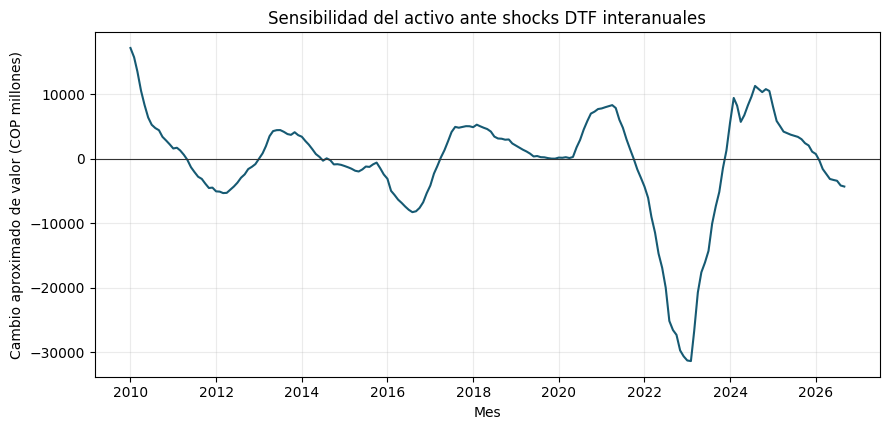

In [4]:
fig, ax = plt.subplots(); ax.plot(x.index, x.delta_value_millions, color='#165a73'); ax.axhline(0,color='#333333',linewidth=.8); ax.set(title='Sensibilidad del activo ante shocks DTF interanuales',ylabel='Cambio aproximado de valor (COP millones)',xlabel='Mes'); fig.tight_layout(); plt.show()

## Interpretación y límites

Es una aproximación lineal de un solo activo, no una medición EVE del balance ni un cálculo regulatorio de IRRBB. Omite pasivos, curvas por plazo, convexidad, opcionalidad y comportamiento de depósitos; requiere flujos de ambos lados y supuestos aprobados.

## Sensibilidad a la duración supuesta

El shock interanual de septiembre de 2026 se aplica al mismo activo hipotético con duraciones de uno, tres y cinco años. El valor se expresa en COP millones y la relación lineal es una aproximación local: no incorpora convexidad ni reproduce la valoración con flujos descontados.

In [5]:
assert df.dtf_promedio.dropna().between(0,100).all(), 'DTF fuera de rango porcentual'
assert x.shock_pp.notna().all() and x.index.is_unique
shock_last = x.shock_pp.iloc[-1]
durations = pd.DataFrame({'duracion_modificada_anios':[1.0,3.0,5.0]})
durations['variacion_COP_millones']=-value_millions*durations.duracion_modificada_anios*shock_last/100
durations['variacion_pct_valor']=100*durations.variacion_COP_millones/value_millions
assert abs(durations.loc[durations.duracion_modificada_anios.eq(3),'variacion_COP_millones'].iloc[0]-x.delta_value_millions.iloc[-1]) < 1e-8
print('Shock DTF:',round(shock_last,4),'pp; valor hipotético COP millones:',value_millions)
durations.round(2)

Shock DTF: 1.4403 pp; valor hipotético COP millones: 100000


,duracion_modificada_anios,variacion_COP_millones,variacion_pct_valor
0,1.0,-1440.33,-1.44
1,3.0,-4321.00,-4.32
2,5.0,-7201.67,-7.20


La sensibilidad crece proporcionalmente a la duración asumida. DTF es una tasa de corto plazo usada aquí como proxy; no identifica cambios de una curva completa ni el impacto neto de activos y pasivos.

## Literatura y elección del benchmark

La [guía BCBS SRP98](https://www.bis.org/committees/bcbs/basel-framework/standard/srp/98/inforce/2019-12-15/published/2019-12-15) distingue el impacto en valor económico y en ingresos; una pérdida de valor económico no equivale automáticamente a una pérdida contable. El ejercicio DTF usa un solo activo hipotético y no calcula EVE ni NII. Como contraste numérico, el siguiente ejemplo compara duración lineal con valoración exacta de un bono cero cupón con capitalización anual; no se infieren posiciones reales.

## Variante: duración frente a valoración exacta

Se fija un cero cupón hipotético de tres años, rendimiento inicial de 5 % y valor inicial COP 100.000 millones. La duración modificada exacta en la base es `T / (1+y)`. Los shocks paralelos −100, +100 y +300 pb son ilustrativos; no son escenarios regulatorios calibrados para Colombia. La diferencia frente al precio exacto muestra el efecto de curvatura para ese instrumento.

In [6]:
import numpy as np
T=3; y0=0.05; V0=100_000; dur=T/(1+y0)
shocks=np.array([-0.01,0.01,0.03]); assert ((1+y0+shocks)>0).all()
exact=V0*((1+y0)/(1+y0+shocks))**T-V0
linear=-V0*dur*shocks
benchmark=pd.DataFrame({'shock_pb':shocks*10000,'lineal_COP_millones':linear,'exacto_COP_millones':exact,'diferencia_exacta_menos_lineal':exact-linear})
assert abs(V0*((1+y0)/(1+y0))**T-V0)<1e-8
benchmark.round(2)

,shock_pb,lineal_COP_millones,exacto_COP_millones,diferencia_exacta_menos_lineal
0,-100.0,2857.14,2912.44,55.30
1,100.0,-2857.14,-2803.57,53.57
2,300.0,-8571.43,-8104.00,467.43
